In [1]:
import numpy as np
import os
import sys
import matplotlib.pyplot as plt
import cv2

sys.path.append("..")
from tflite_inference import TFLiteInferer, TFLiteMerged

%load_ext autoreload
%autoreload 2

2025-09-17 12:02:56.067935: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-09-17 12:02:56.084703: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-09-17 12:02:56.089728: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-09-17 12:02:56.102255: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-09-17 12:02:56.984315: W tensorflow/compiler/tf2

TensorFlow version:  2.17.0


In [2]:
def draw_output(img, output):
    tmp = img.copy()
    for box in output:
        x1, y1, w, h, conf, _, x, y = box
        x2 = x1 + w
        y2 = y1 + h
        cv2.rectangle(tmp, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), 2)
        cv2.circle(tmp, (int(x), int(y)), 9, (0, 255, 0), -1)
        cv2.putText(tmp, f"{conf:.2f}", (int(x1), int(y1 - 10)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)
    plt.imshow(tmp)

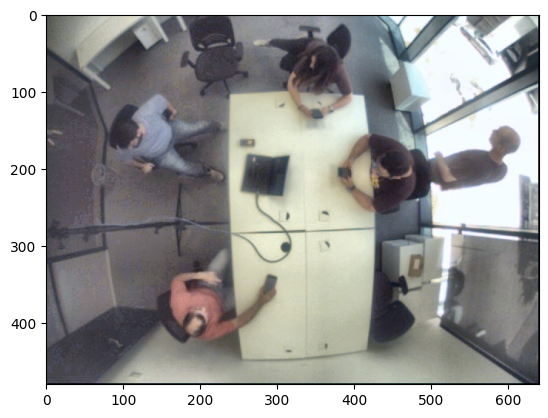

In [3]:
img_pth = "/home/klymy/data/cam4_revB/yolo_dataset/batch1_5_margin_15_bg_wb_alif_clahe/images/val/4.2_batch2____4.2_H_cam_262_spacesMR_201.jpg"
img = cv2.imread(img_pth)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.imshow(img)

In [4]:
combined_quant_model = TFLiteInferer(
    yolo_pth="results/cam3_revB_batch1_5_margin_15_rq_bg_wb_alif_clahe_box_01_dfl_01_2nd/weights/best_non_separated_saved_model/best_full_integer_quant.tflite",
    conf_th=0.25,
    iou_th=0.35
)

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


In [5]:
scores, bboxes = combined_quant_model.infer_no_head(img, quantized_output=False)
scores.shape, bboxes.shape

((1, 2100, 1), (1, 2100, 6))

In [6]:
raw_outputs = np.concatenate([bboxes[:, :, :4], scores, bboxes[:, :, 4:]], axis=-1)
outputs = combined_quant_model.post_process(raw_outputs)
outputs

array([[ 61.28285217, 122.56570435, 183.84855652, 122.56570435,
          0.91015625,   0.        , 164.69766235, 164.69766235],
       [367.69711304, 183.84855652, 122.56570435,  61.28285217,
          0.91015625,   0.        , 409.82907104, 206.82962036],
       [306.41424561,  30.64142609,  91.92427826, 122.56570435,
          0.86328125,   0.        , 371.52728271, 103.41481018],
       [486.43264771, 122.56570435, 122.56570435, 122.56570435,
          0.86328125,   0.        , 494.09298706, 206.82962036],
       [183.84855652, 306.41424561, 122.56570435, 122.56570435,
          0.86328125,   0.        , 245.13140869, 371.52728271]])

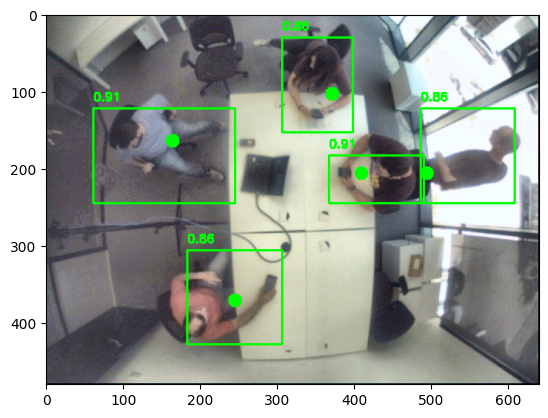

In [7]:
draw_output(img, outputs)

In [8]:
combined_quant_model = TFLiteInferer(
    yolo_pth="tst_weights_pt/weights/best_saved_model/best_full_integer_quant.tflite",
    conf_th=0.25,
    iou_th=0.35
)

In [9]:
scores, bboxes = combined_quant_model.infer_no_head(img, quantized_output=False)
scores.shape, bboxes.shape

((1, 2100, 1), (1, 2100, 6))

In [11]:
raw_outputs = np.concatenate([bboxes[:, :, :4], scores, bboxes[:, :, 4:]], axis=-1)
outputs = combined_quant_model.post_process(raw_outputs)
outputs

array([[ 61.28285217, 122.56570435, 183.84855652, 122.56570435,
          0.91015625,   0.        , 164.69766235, 164.69766235],
       [367.69711304, 183.84855652, 122.56570435,  61.28285217,
          0.91015625,   0.        , 409.82907104, 206.82962036],
       [306.41424561,  30.64142609,  91.92427826, 122.56570435,
          0.86328125,   0.        , 371.52728271, 103.41481018],
       [486.43264771, 122.56570435, 122.56570435, 122.56570435,
          0.86328125,   0.        , 494.09298706, 206.82962036],
       [183.84855652, 306.41424561, 122.56570435, 122.56570435,
          0.86328125,   0.        , 245.13140869, 371.52728271]])

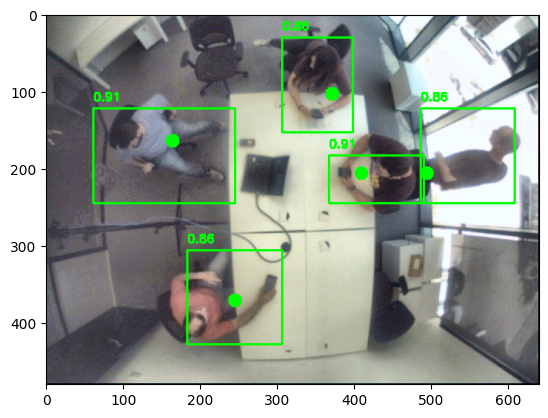

In [12]:
draw_output(img, outputs)